# PathSnap: Data Exploration & Preprocessing
Covers: dataset inventory, EDA plots, candidate generation, label assignment, candidate miss-rate analysis, Folium map.

**Before running:** keep `train/` and `student_test/` in the repository, or set the paths in the *Config* cell. Colab mounting is optional.
Every figure here is produced from the actual data, so keep the outputs for the report and say which partition each one used.

## 1. Setup

In [1]:
!pip -q install shapely pyproj folium


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Config: edit these paths

In [2]:
import os
# Mount Drive if running in Colab (ignored elsewhere)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

# Folders containing the <trip>/<trip>.track/.nodes/.arcs/.route files of each partition
from pathlib import Path

NOTEBOOK_DIR = Path.cwd()
TRAIN_DIR   = os.environ.get("PATHSNAP_TRAIN",   str(NOTEBOOK_DIR / "train"))
STUDENT_DIR = os.environ.get("PATHSNAP_STUDENT", str(NOTEBOOK_DIR / "student_test"))
OUT_DIR     = os.environ.get("PATHSNAP_OUT",     str(NOTEBOOK_DIR / "processed"))
# NOTE: do NOT point anything at the evaluator-test data.
os.makedirs(OUT_DIR, exist_ok=True)
print(TRAIN_DIR, os.path.isdir(TRAIN_DIR))

c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\train True


## 3. Preprocessing module
This cell writes `preprocess.py` (same file that goes in the GitHub repo under `src/`). Read it: you need to explain every function in the viva.

In [3]:
%%writefile preprocess.py
"""
PathSnap preprocessing: loading, projection, arc cleaning, candidate
generation and reference-label assignment for ONE trip.

Design notes (be ready to explain these in the viva):
  * arc_id is the 0-based ROW INDEX of the .arcs file, so we never drop
    rows from the arcs array; bad arcs are masked instead.
  * All geometry is done in UTM zone 32N (EPSG:32632, metres). The data
    lies at lon ~8.6E, which is inside zone 32 (6E-12E).
  * Labels: .route is a sequence of arcs, not one arc per GPS point, so we
    assign each point to a route arc with a monotone (order-preserving)
    dynamic program that minimises total point-to-arc distance.
"""
import os
import numpy as np
import pandas as pd
from pyproj import Transformer
from shapely import STRtree, linestrings, points as shp_points

CRS_UTM = "EPSG:32632"
_tf = Transformer.from_crs("EPSG:4326", CRS_UTM, always_xy=True)


# ----------------------------------------------------------------- loading
def load_trip(folder, trip_id, need_route=True):
    """trip_id like '00000001'. Returns dict of raw arrays."""
    def p(ext):
        nested = os.path.join(folder, trip_id, f"{trip_id}.{ext}")
        flat = os.path.join(folder, f"{trip_id}.{ext}")
        return nested if os.path.exists(nested) else flat
    track = np.loadtxt(p("track"))                  # lon, lat, t
    nodes = np.loadtxt(p("nodes"))                  # lon, lat
    arcs = np.loadtxt(p("arcs"), dtype=np.int64)    # from, to
    route = None
    if need_route and os.path.exists(p("route")):
        route = np.loadtxt(p("route"), dtype=np.int64, ndmin=1)
    return dict(track=track, nodes=nodes, arcs=arcs, route=route)


def project(lonlat):
    x, y = _tf.transform(lonlat[:, 0], lonlat[:, 1])
    return np.column_stack([x, y])


# ---------------------------------------------------------------- cleaning
def validate_track(track):
    """Return (clean_track_mask, report). Flags NaN, out-of-range coords,
    non-increasing timestamps. Does NOT interpolate or drop silently."""
    lon, lat, t = track[:, 0], track[:, 1], track[:, 2]
    bad_nan = ~np.isfinite(track).all(axis=1)
    bad_rng = (np.abs(lon) > 180) | (np.abs(lat) > 90)
    dt = np.diff(t, prepend=t[0] - 1)
    bad_time = dt <= 0
    keep = ~(bad_nan | bad_rng | bad_time)
    rep = dict(n=len(track), nan=int(bad_nan.sum()), out_of_range=int(bad_rng.sum()),
               non_increasing_time=int(bad_time.sum()),
               max_gap_s=float(np.max(np.diff(t))) if len(t) > 1 else 0.0)
    return keep, rep


def build_network(nodes_ll, arcs):
    """Project nodes, build arc geometry, mask degenerate arcs."""
    nxy = project(nodes_ll)
    a, b = nxy[arcs[:, 0]], nxy[arcs[:, 1]]
    length = np.hypot(*(b - a).T)
    valid = length > 0.5                     # drop zero / sub-0.5 m arcs from the index
    bearing = np.degrees(np.arctan2(b[:, 0] - a[:, 0], b[:, 1] - a[:, 1])) % 360  # 0=N, clockwise
    return dict(nxy=nxy, a=a, b=b, length=length, valid=valid, bearing=bearing, arcs=arcs)


def build_index(net):
    ids = np.flatnonzero(net["valid"])
    geoms = linestrings(np.stack([net["a"][ids], net["b"][ids]], axis=1))
    return STRtree(geoms), ids, geoms


# ------------------------------------------------------ geometry helpers
def seg_dist_frac(p, a, b):
    """Distance from points p to segments a-b (all (n,2)) and fraction along."""
    ab = b - a
    L2 = np.maximum((ab ** 2).sum(1), 1e-9)
    f = np.clip(((p - a) * ab).sum(1) / L2, 0.0, 1.0)
    proj = a + f[:, None] * ab
    return np.hypot(*(p - proj).T), f


def gps_bearing_speed(xy, t):
    """Heading (deg, 0=N) and speed (m/s) per point from central differences."""
    n = len(xy)
    nxt, prv = np.minimum(np.arange(n) + 1, n - 1), np.maximum(np.arange(n) - 1, 0)
    d = xy[nxt] - xy[prv]
    dt = np.maximum(t[nxt] - t[prv], 1e-6)
    spd = np.hypot(*d.T) / dt
    brg = np.degrees(np.arctan2(d[:, 0], d[:, 1])) % 360
    return brg, spd


# -------------------------------------------------- candidate generation
def generate_candidates(xy, t, net, tree, ids, radius=100.0):
    """All arcs within `radius` m of each GPS point -> DataFrame, one row per
    (point, arc) pair. Contains only raw geometric quantities; richer
    feature engineering (Person 2) builds on top of this."""
    pts = shp_points(xy)
    pi, gi = tree.query(pts, predicate="dwithin", distance=radius)
    arc = ids[gi]
    dist, frac = seg_dist_frac(xy[pi], net["a"][arc], net["b"][arc])
    brg, spd = gps_bearing_speed(xy, t)
    dh = np.abs((brg[pi] - net["bearing"][arc] + 180) % 360 - 180)
    df = pd.DataFrame(dict(pt=pi, arc_id=arc, dist=dist, frac=frac,
                           arc_len=net["length"][arc], arc_bearing=net["bearing"][arc],
                           gps_bearing=brg[pi], head_diff=dh, speed=spd[pi]))
    return df.sort_values(["pt", "dist"], kind="stable").reset_index(drop=True)


# -------------------------------------------------------------- labelling
def assign_reference_arcs(xy, route, net):
    """Monotone assignment of GPS points to reference route arcs.
    dp[i, j] = d(i, route[j]) + min_{k<=j} dp[i-1, k]   (order preserved)
    Returns (label_arc_id per point, distance to that arc)."""
    a, b = net["a"][route], net["b"][route]
    n, m = len(xy), len(route)
    D = np.empty((n, m))
    for j in range(m):                                   # m ~ few hundred
        D[:, j], _ = seg_dist_frac(xy, np.broadcast_to(a[j], xy.shape), np.broadcast_to(b[j], xy.shape))
    dp = np.empty((n, m)); bp = np.empty((n, m), dtype=np.int32)
    dp[0] = D[0]
    for i in range(1, n):
        prev = dp[i - 1]
        cm = np.minimum.accumulate(prev)                 # best cost over k<=j
        # argmin index of running min
        idx = np.arange(m)
        is_new = np.r_[True, prev[1:] < cm[:-1]]
        am = np.maximum.accumulate(np.where(is_new, idx, 0))
        dp[i] = D[i] + cm
        bp[i] = am
    j = int(np.argmin(dp[-1])); path = np.empty(n, dtype=np.int64)
    for i in range(n - 1, -1, -1):
        path[i] = j
        j = bp[i, j]
    return route[path], D[np.arange(n), path], path


def label_candidates(cands, label_arc):
    cands["label"] = (cands["arc_id"].values == label_arc[cands["pt"].values]).astype(np.int8)
    return cands


# ------------------------------------------------------------ one-call API
def process_trip(folder, trip_id, radius=100.0, with_labels=True):
    raw = load_trip(folder, trip_id, need_route=with_labels)
    keep, rep = validate_track(raw["track"])
    track = raw["track"][keep]
    xy, t = project(track[:, :2]), track[:, 2]
    net = build_network(raw["nodes"], raw["arcs"])
    tree, ids, _ = build_index(net)
    cands = generate_candidates(xy, t, net, tree, ids, radius)
    out = dict(track=track, xy=xy, t=t, net=net, cands=cands, report=rep, route=raw["route"])
    if with_labels and raw["route"] is not None:
        lab, ldist, path = assign_reference_arcs(xy, raw["route"], net)
        cands = label_candidates(cands, lab)
        # per-point diagnostics: is the reference arc inside the candidate set?
        hit = cands.groupby("pt")["label"].max().reindex(range(len(xy)), fill_value=0)
        out.update(label_arc=lab, label_dist=ldist, route_pos=path, point_has_true_candidate=hit.values.astype(bool))
        out["cands"] = cands
    return out


Writing preprocess.py


## 4. Imports

In [4]:
import glob, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from preprocess import *
plt.rcParams["figure.dpi"] = 110

## 5. Dataset inventory (raw files only)
Per trip: points, time gaps, network size, connectivity, route length. Do this for each partition and keep the tables.

In [5]:
def trip_files(folder):
    nested = sorted(glob.glob(os.path.join(folder, "*", "*.track")))
    flat = sorted(glob.glob(os.path.join(folder, "*.track")))
    return nested if nested else flat


def inventory(folder, partition):
    rows = []
    for f in trip_files(folder):
        tid = os.path.splitext(os.path.basename(f))[0]
        r = load_trip(folder, tid)
        tr, nd, ar, rt = r["track"], r["nodes"], r["arcs"], r["route"]
        dt = np.diff(tr[:, 2])
        net = build_network(nd, ar)
        ncomp, lab = connected_components(
            coo_matrix((np.ones(len(ar)), (ar[:, 0], ar[:, 1])), shape=(len(nd),) * 2), directed=False)
        deg = np.bincount(np.r_[ar[:, 0], ar[:, 1]], minlength=len(nd))
        rows.append(dict(partition=partition, trip=tid, n_points=len(tr),
            nan_rows=int((~np.isfinite(tr)).any(1).sum()), dup_time=int((dt <= 0).sum()),
            pct_1s=round(100 * (dt == 1).mean(), 1), max_gap_s=dt.max(), duration_s=tr[-1, 2] - tr[0, 2],
            lon_span=round(np.ptp(tr[:, 0]), 4), lat_span=round(np.ptp(tr[:, 1]), 4),
            n_nodes=len(nd), n_arcs=len(ar), zero_len_arcs=int((~net["valid"]).sum()),
            components=ncomp, isolated_nodes=int((deg == 0).sum()),
            has_route=rt is not None, route_arcs=0 if rt is None else len(rt),
            route_connected=None if rt is None else bool((ar[rt[:-1], 1] == ar[rt[1:], 0]).all()),
            route_km=None if rt is None else round(net["length"][rt].sum() / 1000, 1)))
    return pd.DataFrame(rows)

inv_train = inventory(TRAIN_DIR, "train")
inv_train.to_csv(os.path.join(OUT_DIR, "inventory_train.csv"), index=False)
display(inv_train.describe().T.round(2))
inv_train.head()

c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\preprocess.py:65: RuntimeWarning: invalid value encountered in subtract
  length = np.hypot(*(b - a).T)
c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\preprocess.py:67: RuntimeWarning: invalid value encountered in subtract
  bearing = np.degrees(np.arctan2(b[:, 0] - a[:, 0], b[:, 1] - a[:, 1])) % 360  # 0=N, clockwise


,count,mean,std,min,25%,50%,75%,max
n_points,80.0,2605.21,3312.35,361.00,945.75,1529.00,2792.75,19313.00
nan_rows,80.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
dup_time,80.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
pct_1s,80.0,93.83,11.74,53.10,95.85,99.10,100.00,100.00
max_gap_s,80.0,2706.40,18017.45,1.00,1.75,11.00,73.75,153064.00
duration_s,80.0,5680.40,18252.16,451.00,1225.30,1710.00,3765.00,154030.00
lon_span,80.0,0.19,0.22,0.01,0.05,0.09,0.25,1.10
lat_span,80.0,0.11,0.13,0.01,0.03,0.05,0.13,0.68
n_nodes,80.0,24168.56,32272.30,299.00,3487.75,9608.00,28846.75,155003.00
n_arcs,80.0,48461.30,64738.84,649.00,7061.75,19526.50,58003.25,307392.00


,partition,trip,n_points,nan_rows,dup_time,pct_1s,max_gap_s,duration_s,lon_span,lat_span,n_nodes,n_arcs,zero_len_arcs,components,isolated_nodes,has_route,route_arcs,route_connected,route_km
0,train,00000001,1315,0,0,98.1,16.0,1357.000,0.0773,0.3678,88809,165790,93,175,0,True,525,True,49.9
1,train,00000002,7243,0,0,97.4,160.0,8933.156,0.0509,0.0371,7936,16139,0,14,0,True,262,False,8.0
2,train,00000003,821,0,0,99.6,2.0,823.000,0.0474,0.0305,9138,18028,4,42,0,True,79,True,5.2
3,train,00000004,1064,0,0,53.8,51.0,5217.000,0.1173,0.1287,7350,15499,2,12,0,True,320,True,25.6
4,train,00000005,1045,0,0,100.0,1.0,1044.000,0.0587,0.2555,898,1579,0,3,0,True,105,True,32.3


In [6]:
# Student-test partition (development evaluation)
inv_student = inventory(STUDENT_DIR, "student_test")
inv_student.to_csv(os.path.join(OUT_DIR, "inventory_student.csv"), index=False)
inv_student

,partition,trip,n_points,nan_rows,dup_time,pct_1s,max_gap_s,duration_s,lon_span,lat_span,n_nodes,n_arcs,zero_len_arcs,components,isolated_nodes,has_route,route_arcs,route_connected,route_km
0,student_test,00000000,2503,0,0,100.0,2.0,2503.0,0.7150,0.1740,8542,18196,0,100,0,True,179,True,56.0
1,student_test,00000007,1354,0,0,100.0,1.0,1353.0,0.1491,0.1077,2061,4369,0,6,0,True,123,True,30.0
2,student_test,00000009,1049,0,0,99.9,2.0,1049.0,0.0746,0.0169,6745,13106,6,8,0,True,429,True,11.4
3,student_test,00000040,2995,0,0,100.0,1.0,2994.0,0.2232,0.2412,12945,27026,2,15,0,True,309,True,51.8
4,student_test,00000052,262,0,0,98.5,2.0,265.0,0.0380,0.0323,1770,3577,2,7,0,True,95,True,5.5
5,student_test,00000056,3958,0,0,99.0,3.0,4000.0,0.0758,0.0374,14759,27631,0,24,0,True,1323,True,89.7
6,student_test,00000065,768,0,0,98.6,210.0,1037.0,0.0667,0.0263,6448,13184,4,5,0,True,145,True,8.5
7,student_test,00000076,1486,0,0,86.1,32.0,2266.0,0.0724,0.0884,26635,56027,2,40,0,True,374,False,14.3
8,student_test,00000077,3911,0,0,100.0,1.0,3910.0,0.0525,0.0598,4424,9622,2,11,0,True,268,True,16.9
9,student_test,00000091,874,0,0,100.0,1.0,873.0,0.0325,0.0465,6360,12303,3,11,0,True,232,True,9.4


## 6. One trip in detail (train partition)

In [7]:
trip_ids = [os.path.splitext(os.path.basename(f))[0] for f in trip_files(TRAIN_DIR)]
TID = trip_ids[0]      # change to explore other trips
t0 = time.time()
o = process_trip(TRAIN_DIR, TID, radius=100)
print("trip", TID, "| processed in", round(time.time() - t0, 1), "s")
print("data-quality report:", o["report"])
c = o["cands"]
print("candidate rows:", c.shape, "| per point: mean %.1f, min %d, max %d" % (
    len(c) / len(o["xy"]), c.groupby("pt").size().min(), c.groupby("pt").size().max()))
print("positives:", int(c.label.sum()), "| pos rate: %.4f" % c.label.mean())
print("candidate miss rate: %.4f" % (1 - o["point_has_true_candidate"].mean()))
print("nearest-arc Top-1 baseline: %.4f" % c.groupby("pt").first().label.mean())
c.head(10).round(2)

trip 00000001 | processed in 0.4 s
data-quality report: {'n': 1315, 'nan': 0, 'out_of_range': 0, 'non_increasing_time': 0, 'max_gap_s': 16.0}
candidate rows: (44702, 10) | per point: mean 34.0, min 2, max 160
positives: 1315 | pos rate: 0.0294
candidate miss rate: 0.0000
nearest-arc Top-1 baseline: 0.7871


,pt,arc_id,dist,frac,arc_len,arc_bearing,gps_bearing,head_diff,speed,label
0,0,64973,0.72,0.11,293.24,7.62,8.93,1.31,43.63,1
1,0,117639,15.13,0.51,1020.44,187.69,8.93,178.76,43.63,0
2,0,2641,32.20,1.00,425.05,7.49,8.93,1.44,43.63,0
3,0,53932,93.01,0.15,169.04,357.09,8.93,11.84,43.63,0
4,0,50652,93.01,0.85,169.04,177.09,8.93,168.16,43.63,0
5,0,50585,96.62,1.00,225.13,279.94,8.93,88.99,43.63,0
6,0,53934,96.62,0.00,225.13,99.94,8.93,91.01,43.63,0
7,0,50653,96.62,1.00,274.57,353.87,8.93,15.06,43.63,0
8,0,53933,96.62,0.00,274.57,173.87,8.93,164.94,43.63,0
9,1,64973,0.28,0.26,293.24,7.62,6.93,0.69,46.45,1


### 6a. EDA plots

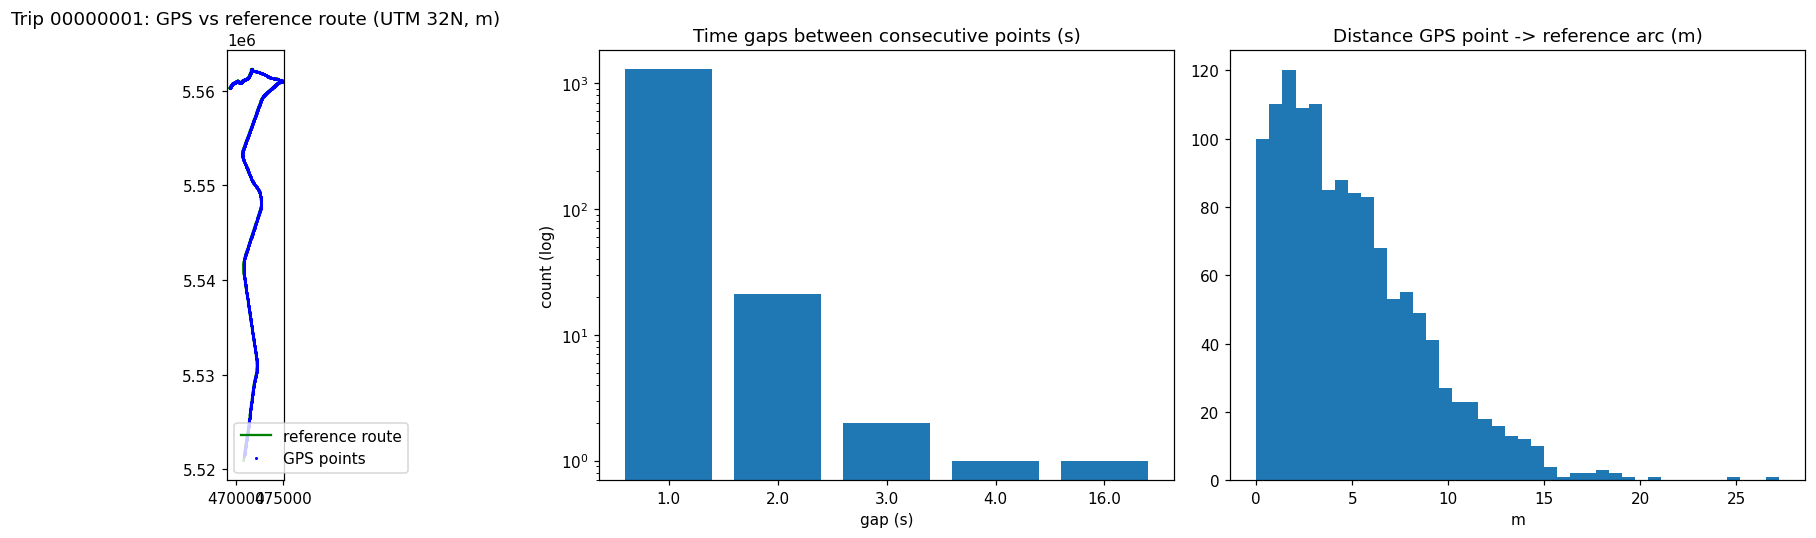

speed km/h: median 149, 95% 212, max 261


In [8]:
xy, t, net, route = o["xy"], o["t"], o["net"], o["route"]
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# trajectory + reference route (projected metres)
for k, arc in enumerate(route):
    ax[0].plot([net["a"][arc, 0], net["b"][arc, 0]], [net["a"][arc, 1], net["b"][arc, 1]], "g-", lw=1.5,
               label="reference route" if k == 0 else None)
ax[0].plot(xy[:, 0], xy[:, 1], "b.", ms=2, label="GPS points")
ax[0].set_title(f"Trip {TID}: GPS vs reference route (UTM 32N, m)"); ax[0].set_aspect("equal"); ax[0].legend()

# time gaps
dt = np.diff(t)
vals, cnts = np.unique(dt, return_counts=True)
ax[1].bar(vals.astype(str), cnts); ax[1].set_yscale("log")
ax[1].set_title("Time gaps between consecutive points (s)"); ax[1].set_xlabel("gap (s)"); ax[1].set_ylabel("count (log)")

# distance from each GPS point to its reference arc = GPS noise estimate
ax[2].hist(o["label_dist"], bins=40)
ax[2].set_title("Distance GPS point -> reference arc (m)"); ax[2].set_xlabel("m")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"eda_{TID}.png")); plt.show()

speed = np.hypot(*np.diff(xy, axis=0).T) / dt
print("speed km/h: median %.0f, 95%% %.0f, max %.0f" % tuple(np.r_[np.median(speed), np.percentile(speed, 95), speed.max()] * 3.6))

### 6b. Candidate-radius analysis
A candidate set is only useful if it contains the reference arc. We generate candidates once at the largest radius and measure the miss rate for smaller radii by filtering on distance. This justifies the radius choice. Uses a sample of **training** trips.

,miss_rate,worst_trip_miss,cands_per_pt
radius,,,
20,0.0849,0.3353,3.6702
30,0.0371,0.1752,5.6051
50,0.0167,0.1198,10.1806
75,0.0119,0.1098,17.1371
100,0.0103,0.0993,25.7797
150,0.0070,0.0696,47.5194
200,0.0060,0.0595,76.3971


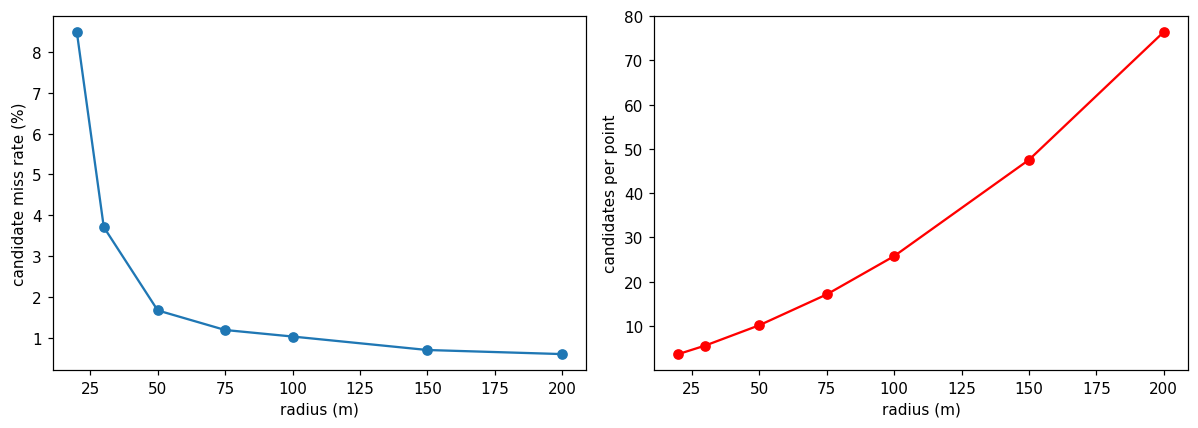

In [9]:
RADII = [20, 30, 50, 75, 100, 150, 200]
SAMPLE = trip_ids[:min(10, len(trip_ids))]          # use all 80 for the final report if time allows
res = []
for tid in SAMPLE:
    oo = process_trip(TRAIN_DIR, tid, radius=max(RADII))
    cc = oo["cands"]; npts = len(oo["xy"])
    for r in RADII:
        hit = cc[(cc.label == 1) & (cc.dist <= r)].pt.nunique()
        n_c = (cc.dist <= r).sum()
        res.append(dict(trip=tid, radius=r, miss_rate=1 - hit / npts, cands_per_pt=n_c / npts))
res = pd.DataFrame(res)
summ = res.groupby("radius").agg(miss_rate=("miss_rate", "mean"), worst_trip_miss=("miss_rate", "max"),
                                 cands_per_pt=("cands_per_pt", "mean")).round(4)
summ.to_csv(os.path.join(OUT_DIR, "radius_analysis.csv"))
display(summ)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(summ.index, summ.miss_rate * 100, "o-"); ax[0].set_xlabel("radius (m)"); ax[0].set_ylabel("candidate miss rate (%)")
ax[1].plot(summ.index, summ.cands_per_pt, "o-r"); ax[1].set_xlabel("radius (m)"); ax[1].set_ylabel("candidates per point")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "radius_analysis.png")); plt.show()

### 6c. Folium map (GPS, road network, reference route, top-3 nearest candidates)

In [10]:
import folium
from pyproj import Transformer
inv = Transformer.from_crs(CRS_UTM, "EPSG:4326", always_xy=True)
def ll(p): lon, lat = inv.transform(p[0], p[1]); return [lat, lon]

lo, hi = 0, min(len(xy), 400)                     # first 400 points keeps the map light; change as needed
center = ll(xy[lo:hi].mean(0))
m = folium.Map(location=center, zoom_start=15, tiles="OpenStreetMap")

g_net = folium.FeatureGroup("Road network (arcs near trip)", show=False)
g_gps = folium.FeatureGroup("GPS observations")
g_ref = folium.FeatureGroup("Reference route")
seen = set()
for arc in c[c.pt.between(lo, hi - 1)].arc_id.unique():
    folium.PolyLine([ll(net["a"][arc]), ll(net["b"][arc])], color="gray", weight=2, opacity=.6).add_to(g_net)
for arc in route:
    if arc in set(o["label_arc"][lo:hi]):
        folium.PolyLine([ll(net["a"][arc]), ll(net["b"][arc])], color="green", weight=5, opacity=.8,
                        tooltip=f"ref arc {arc}").add_to(g_ref)
for i in range(lo, hi):
    folium.CircleMarker(ll(xy[i]), radius=3, color="blue", fill=True,
                        tooltip=f"pt {i}, t={t[i]:.0f}s, ref arc {o['label_arc'][i]}").add_to(g_gps)
for g in (g_net, g_ref, g_gps): g.add_to(m)
folium.LayerControl().add_to(m)
legend = """<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px;border:1px solid grey;font-size:13px">
<b>Legend</b><br><span style="color:blue">&#9679;</span> GPS points<br><span style="color:green">&#9632;</span> Reference route<br><span style="color:gray">&#9632;</span> Road network</div>"""
m.get_root().html.add_child(folium.Element(legend))
m.save(os.path.join(OUT_DIR, f"map_{TID}.html"))
m

## 7. Process all training trips and save candidate tables

In [11]:
rows = []
for tid in trip_ids:
    oo = process_trip(TRAIN_DIR, tid, radius=100)
    cc = oo["cands"]
    cc.assign(trip=tid).to_csv(os.path.join(OUT_DIR, f"train_{tid}_cands.csv.gz"), index=False)
    rows.append(dict(trip=tid, n_pts=len(oo["xy"]), n_cands=len(cc),
                     miss_rate=1 - oo["point_has_true_candidate"].mean(),
                     label_dist_med=np.median(oo["label_dist"]), label_dist_max=oo["label_dist"].max(),
                     nearest_top1=cc.groupby("pt").first().label.mean()))
prep = pd.DataFrame(rows); prep.to_csv(os.path.join(OUT_DIR, "preprocess_summary_train.csv"), index=False)
display(prep.describe().round(4))
prep.sort_values("miss_rate", ascending=False).head()

c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\preprocess.py:65: RuntimeWarning: invalid value encountered in subtract
  length = np.hypot(*(b - a).T)
c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\preprocess.py:67: RuntimeWarning: invalid value encountered in subtract
  bearing = np.degrees(np.arctan2(b[:, 0] - a[:, 0], b[:, 1] - a[:, 1])) % 360  # 0=N, clockwise
c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\preprocess.py:91: RuntimeWarning: invalid value encountered in subtract
  d = xy[nxt] - xy[prv]
c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\preprocess.py:80: RuntimeWarning: invalid value encountered in subtract
  ab = b - a
c:\Users\rajgo\WORK\SEM5\ML_Hackathon\PathSnap_ML_Hackathon\preprocess.py:82: RuntimeWarning: invalid value encountered in subtract
  f = np.clip(((p - a) * ab).sum(1) / L2, 0.0, 1.0)


,n_pts,n_cands,miss_rate,label_dist_med,label_dist_max,nearest_top1
count,80.0000,80.0000,80.0000,79.0000,79.0000,79.0000
mean,2605.2125,50673.4250,0.0339,8.9845,81.1822,0.5550
std,3312.3454,44589.6507,0.1556,20.0622,113.4430,0.1609
min,361.0000,0.0000,0.0000,3.6373,19.9042,0.0732
25%,945.7500,20077.5000,0.0000,4.4366,29.4890,0.4446
50%,1529.0000,38490.0000,0.0000,5.0077,37.7162,0.5191
75%,2792.7500,62625.0000,0.0000,6.3447,70.7547,0.6587
max,19313.0000,226192.0000,1.0000,140.1979,700.4133,0.9560


,trip,n_pts,n_cands,miss_rate,label_dist_med,label_dist_max,nearest_top1
46,00000057,1645,0,1.000000,NaN,NaN,NaN
44,00000054,19313,209609,0.852120,140.197940,241.450306,0.073588
26,00000033,5844,176423,0.509754,123.097099,161.357879,0.073238
1,00000002,7243,226192,0.099268,5.774628,569.657738,0.439759
64,00000081,3224,23424,0.049938,10.059713,369.037389,0.722168


In [12]:
# Same for student-test trips (used later for development evaluation, never for fitting)
srows = []
for f in trip_files(STUDENT_DIR):
    tid = os.path.splitext(os.path.basename(f))[0]
    oo = process_trip(STUDENT_DIR, tid, radius=100)
    oo["cands"].assign(trip=tid).to_csv(os.path.join(OUT_DIR, f"student_{tid}_cands.csv.gz"), index=False)
    srows.append(dict(trip=tid, miss_rate=1 - oo["point_has_true_candidate"].mean(),
                      nearest_top1=oo["cands"].groupby("pt").first().label.mean()))
pd.DataFrame(srows)

,trip,miss_rate,nearest_top1
0,00000000,0.000000,0.561326
1,00000007,0.000000,0.517725
2,00000009,0.000000,0.478551
3,00000040,0.000000,0.635726
4,00000052,0.000000,0.854962
5,00000056,0.005306,0.679889
6,00000065,0.000000,0.614583
7,00000076,0.000000,0.451548
8,00000077,0.000000,0.550499
9,00000091,0.000000,0.596110


## 8. Notes to record for the report
- Partition used for each analysis (sections 5-7 above state it).
- Labelling assumption: monotone assignment of points to reference route arcs; reference route is treated as reference, not perfect truth.
- Chosen candidate radius and the miss-rate evidence from 6b.
- Data-quality issues found (gaps, zero-length arcs, components, anything odd in `inventory_*.csv`).